# AquaGuard AI — Final Model Comparison & Production Selection
**Task:** Systematic Evaluation and Final Model Selection for Campus Water SCADA Monitoring  
**Architecture:** Dual-Engine AI Architecture
- **Engine 1: Unsupervised Abnormal Consumption Engine** (Smart Meter Volume Monitoring)
- **Engine 2: Supervised Multiclass Leak Identification Engine** (Telemetry & Hydraulic Rupture Diagnosis)

---
### Strict Scientific Guardrails:
- **No Composite Score Muddling:** Metric dimensions (statistical quality, latency, model footprint, operational recovery, business savings) are reported transparently without combining incompatible units into an unexplained heuristic.
- **Dedicated Domain Leaderboards:** Unsupervised anomaly detectors and supervised multiclass classifiers are benchmarked independently against task-appropriate baselines.
- **Definitive Production Selection:** Selection of the optimal model for each task with clear trade-off analysis.


### 🏆 MASTER PRODUCTION MODEL SELECTION & TEST ACCURACY SUMMARY (ALL 6 MODELS)

#### Engine 1: Abnormal Consumption Detection (Unsupervised)
| Model | Model File Location | Test Accuracy (%) | Exact Accuracy | F1-Score | Production Status |
|---|---|:---:|:---:|:---:|:---:|
| **One-Class SVM** | `models/anomaly/best_anomaly_model.joblib` | **99.89%** | `0.998885` | **0.7451** | **SELECTED FOR PRODUCTION** |
| **Local Outlier Factor** | `models/anomaly/lof.joblib` | **99.89%** | `0.998928` | 0.6988 | Evaluated |
| **Isolation Forest** | `models/anomaly/isolation_forest.joblib` | **99.55%** | `0.995499` | 0.1860 | Evaluated |

#### Engine 2: Hydraulic Leak Identification (Supervised Multiclass)
| Model | Model File Location | Test Accuracy (%) | Exact Accuracy | Leak Recall | Production Status |
|---|---|:---:|:---:|:---:|:---:|
| **XGBoost Classifier** | `models/leak/best_leak_model.joblib` | **99.79%** | `0.997942` | **100.00%** | **SELECTED FOR PRODUCTION** |
| **Random Forest** | `models/leak/random_forest.joblib` | **99.65%** | `0.996549` | **100.00%** | Evaluated |
| **Extra Trees** | `models/leak/extra_trees.joblib` | **98.80%** | `0.988019` | **100.00%** | Evaluated |


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

os.makedirs('../results/figures', exist_ok=True)
os.makedirs('results/figures', exist_ok=True)

# Load metric reports
base_res = '../results' if os.path.exists('../results') else 'results'
df_abn_metrics = pd.read_csv(os.path.join(base_res, 'anomaly_model_metrics.csv'))
df_leak_metrics = pd.read_csv(os.path.join(base_res, 'leak_model_metrics.csv'))
df_operational = pd.read_csv(os.path.join(base_res, 'operational_metrics.csv'))
df_business = pd.read_csv(os.path.join(base_res, 'business_kpis.csv'))

print("All experimental metric artifacts loaded successfully!")


All experimental metric artifacts loaded successfully!


## 1. Leaderboard A: Abnormal Consumption (Unsupervised Detection)
Evaluating Isolation Forest, Local Outlier Factor (novelty=True), and One-Class SVM on the untouched test partition.


In [2]:
leaderboard_a = df_abn_metrics[[
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'FPR', 'ROC-AUC', 'PR-AUC',
    'Event Detection Rate', 'Avg Detection Delay (min)', 'Avg Latency (ms)', 'P95 Latency (ms)', 'Model Size (KB)'
]].copy()

# Add Groundedness from operational table
g_abn = df_operational[df_operational['Domain'] == 'Abnormal Consumption'].set_index('Model')['Groundedness'].to_dict()
leaderboard_a['Groundedness'] = leaderboard_a['Model'].map(g_abn)

display(leaderboard_a.sort_values('F1-Score', ascending=False))


,Model,Accuracy,Precision,Recall,F1-Score,FPR,ROC-AUC,PR-AUC,Event Detection Rate,Avg Detection Delay (min),Avg Latency (ms),P95 Latency (ms),Model Size (KB),Groundedness
2,One-Class SVM,0.998885,0.737864,0.752475,0.745098,0.000580,0.785688,0.716218,0.75,0.000000,3.917462,9.728760,32.80,0.997505
1,Local Outlier Factor,0.998928,0.892308,0.574257,0.698795,0.000150,0.995823,0.738412,0.75,0.000000,19.759439,88.742555,8598.60,0.997505
0,Isolation Forest,0.995499,0.152866,0.237624,0.186047,0.002857,0.896905,0.222536,0.75,11.666667,197.571386,674.260060,2252.36,0.999001


## 2. Leaderboard B: Leak Identification (Supervised Multiclass)
Evaluating XGBoost, Random Forest, and Extra Trees across Accuracy, Macro F1, Leak Recall, Leak Precision, Misclassification Rates, and Latency.


In [3]:
leaderboard_b = df_leak_metrics[[
    'Model', 'Accuracy', 'Macro F1', 'Leak Recall', 'Leak Precision', 'Leak FPR',
    'Demand-to-Leak Misclassification', 'Sensor-to-Leak Misclassification',
    'Task-Success Rate', 'Avg Latency (ms)', 'P95 Latency (ms)', 'Model Size (KB)'
]].copy()

g_lk = df_operational[df_operational['Domain'] == 'Leak Identification'].set_index('Model')['Groundedness'].to_dict()
leaderboard_b['Groundedness'] = leaderboard_b['Model'].map(g_lk)

display(leaderboard_b.sort_values(['Leak Recall', 'Leak Precision'], ascending=False))


,Model,Accuracy,Macro F1,Leak Recall,Leak Precision,Leak FPR,Demand-to-Leak Misclassification,Sensor-to-Leak Misclassification,Task-Success Rate,Avg Latency (ms),P95 Latency (ms),Model Size (KB),Groundedness
0,XGBoost,0.997942,0.625444,1.0,0.973684,0.000043,0.0,0.02439,1.0,2.289163,2.896285,1104.28,0.996030
2,Extra Trees,0.988019,0.576175,1.0,0.973684,0.000043,0.0,0.00000,1.0,62.637025,139.650830,12920.16,0.979843
1,Random Forest,0.996549,0.559671,1.0,0.961039,0.000064,0.0,0.02439,1.0,47.173893,56.635550,5156.73,0.996533


## 3. Production Model Selection & Trade-Off Analysis

### Best Model Selection:

#### Task 1: Abnormal Consumption Detection -> **One-Class SVM**
- **Highest Primary F1-Score:** 0.7451 (Precision 73.79%, Recall 75.25%), dramatically outperforming Isolation Forest (0.1860).
- **Sub-10ms Inference Latency:** Average inference latency of 3.92 ms and P95 of 9.73 ms, ideal for real-time edge streaming.
- **Ultra-Compact Footprint:** Model artifact size of only 32.8 KB (vs 8,598 KB for LOF and 2,252 KB for Isolation Forest), making it suitable for direct flashing into IoT gateways or edge SCADA nodes.
- **Trade-off:** LOF achieved slightly higher precision (89.23%) but at the expense of lower recall (57.43%), a 262x larger model size, and 5x slower inference.

#### Task 2: Leak Identification -> **XGBoost Classifier**
- **Flawless Critical Leak Recall:** 100.0% test leak recall (zero missed leaks) with 97.37% leak precision.
- **Zero Legitimate Demand False Alarms:** 0.0% demand-to-leak misclassification rate, ensuring morning showers and cafeteria peaks never trigger false technician dispatch.
- **Ultra-Low Latency:** 2.29 ms average query time, 20x faster than Random Forest (47.17 ms) and 27x faster than Extra Trees (62.64 ms).
- **Superior Macro F1:** 0.6254 vs 0.5597 (RF) and 0.5762 (ET).
- **Compact Artifact:** 1,104 KB vs 5,156 KB (RF) and 12,920 KB (ET).


In [4]:
best_selection = {
    'task_1_abnormal_consumption': {
        'best_model': 'One-Class SVM',
        'artifact_path': 'models/anomaly/best_anomaly_model.joblib',
        'key_metrics': {
            'accuracy': float(leaderboard_a.loc[leaderboard_a['Model'] == 'One-Class SVM', 'Accuracy'].values[0]),
            'f1_score': float(leaderboard_a.loc[leaderboard_a['Model'] == 'One-Class SVM', 'F1-Score'].values[0]),
            'precision': float(leaderboard_a.loc[leaderboard_a['Model'] == 'One-Class SVM', 'Precision'].values[0]),
            'recall': float(leaderboard_a.loc[leaderboard_a['Model'] == 'One-Class SVM', 'Recall'].values[0]),
            'event_detection_rate': float(leaderboard_a.loc[leaderboard_a['Model'] == 'One-Class SVM', 'Event Detection Rate'].values[0]),
            'avg_latency_ms': float(leaderboard_a.loc[leaderboard_a['Model'] == 'One-Class SVM', 'Avg Latency (ms)'].values[0]),
            'p95_latency_ms': float(leaderboard_a.loc[leaderboard_a['Model'] == 'One-Class SVM', 'P95 Latency (ms)'].values[0]),
            'model_size_kb': float(leaderboard_a.loc[leaderboard_a['Model'] == 'One-Class SVM', 'Model Size (KB)'].values[0]),
            'groundedness': float(leaderboard_a.loc[leaderboard_a['Model'] == 'One-Class SVM', 'Groundedness'].values[0])
        },
        'selection_rationale': 'Best balance of high F1 (0.7451), near-instant latency (3.92ms), ultra-compact footprint (32.8 KB), and zero detection delay.'
    },
    'task_2_leak_identification': {
        'best_model': 'XGBoost',
        'artifact_path': 'models/leak/best_leak_model.joblib',
        'key_metrics': {
            'accuracy': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'Accuracy'].values[0]),
            'macro_f1': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'Macro F1'].values[0]),
            'leak_recall': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'Leak Recall'].values[0]),
            'leak_precision': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'Leak Precision'].values[0]),
            'leak_fpr': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'Leak FPR'].values[0]),
            'demand_to_leak_rate': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'Demand-to-Leak Misclassification'].values[0]),
            'task_success_rate': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'Task-Success Rate'].values[0]),
            'avg_latency_ms': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'Avg Latency (ms)'].values[0]),
            'p95_latency_ms': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'P95 Latency (ms)'].values[0]),
            'model_size_kb': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'Model Size (KB)'].values[0]),
            'groundedness': float(leaderboard_b.loc[leaderboard_b['Model'] == 'XGBoost', 'Groundedness'].values[0])
        },
        'selection_rationale': '100% leak recall with zero demand-to-leak false alarms, highest macro F1 (0.6254), lightning-fast 2.29ms latency, and compact 1.1MB size.'
    }
}

print(json.dumps(best_selection, indent=2))


{
  "task_1_abnormal_consumption": {
    "best_model": "One-Class SVM",
    "artifact_path": "models/anomaly/best_anomaly_model.joblib",
    "key_metrics": {
      "accuracy": 0.9988854595336076,
      "f1_score": 0.7450980392156863,
      "precision": 0.7378640776699029,
      "recall": 0.7524752475247525,
      "event_detection_rate": 0.75,
      "avg_latency_ms": 3.917461999953957,
      "p95_latency_ms": 9.728760005236811,
      "model_size_kb": 32.8,
      "groundedness": 0.99750499001996
    },
    "selection_rationale": "Best balance of high F1 (0.7451), near-instant latency (3.92ms), ultra-compact footprint (32.8 KB), and zero detection delay."
  },
  "task_2_leak_identification": {
    "best_model": "XGBoost",
    "artifact_path": "models/leak/best_leak_model.joblib",
    "key_metrics": {
      "accuracy": 0.9979423868312756,
      "macro_f1": 0.6254436005501015,
      "leak_recall": 1.0,
      "leak_precision": 0.9736842105263158,
      "leak_fpr": 4.2935039285560944e-05,
   

## 4. Export Configuration and Performance Artifacts
Saving `results/best_model_summary.json`, `results/model_comparison.json`, and `results/experiment_config.json`.


In [5]:
# 1. Best model summary
best_summary_path = os.path.join(base_res, 'best_model_summary.json')
with open(best_summary_path, 'w', encoding='utf-8') as f:
    json.dump(best_selection, f, indent=2)
print(f"Saved: {best_summary_path}")

# 2. Complete model comparison json
comp_data = {
    'abnormal_consumption_leaderboard': leaderboard_a.to_dict(orient='records'),
    'leak_identification_leaderboard': leaderboard_b.to_dict(orient='records'),
    'operational_scorecard': df_operational.to_dict(orient='records'),
    'business_kpis': df_business.to_dict(orient='records')
}
comp_path = os.path.join(base_res, 'model_comparison.json')
with open(comp_path, 'w', encoding='utf-8') as f:
    json.dump(comp_data, f, indent=2)
print(f"Saved: {comp_path}")

# 3. Experiment config json
exp_config = {
    'simulation_parameters': {
        'total_meters': 12,
        'campus_zones': 6,
        'simulation_duration_days': 90,
        'sampling_interval_minutes': 5,
        'total_rows_per_dataset': 311040,
        'date_range': ['2026-07-01 00:00:00', '2026-09-28 23:55:00'],
        'shared_events': 77
    },
    'splitting_strategy': {
        'method': 'chronological_with_event_level_isolation',
        'train_ratio': 0.70,
        'val_ratio': 0.15,
        'test_ratio': 0.15,
        'zero_event_leakage': True
    },
    'operational_simulation_policy': {
        'alert_queue_latency_mins': 2.0,
        'recommendation_latency_mins': 3.0,
        'operator_approval_delay_mins': 15.0,
        'repair_duration_mins': 60.0,
        'hydraulic_stabilization_mins': 10.0,
        'water_tariff_usd_per_m3': 2.50
    },
    'models_trained': [
        'Isolation Forest',
        'Local Outlier Factor (novelty=True)',
        'One-Class SVM',
        'XGBoost Classifier',
        'Random Forest Classifier',
        'Extra Trees Classifier'
    ]
}
exp_path = os.path.join(base_res, 'experiment_config.json')
with open(exp_path, 'w', encoding='utf-8') as f:
    json.dump(exp_config, f, indent=2)
print(f"Saved: {exp_path}")


Saved: ../results\best_model_summary.json
Saved: ../results\model_comparison.json
Saved: ../results\experiment_config.json


## 5. Visual Multi-Model Comparison Chart
Plotting comparative bar charts across primary quality, false positive rate, latency, and footprint.


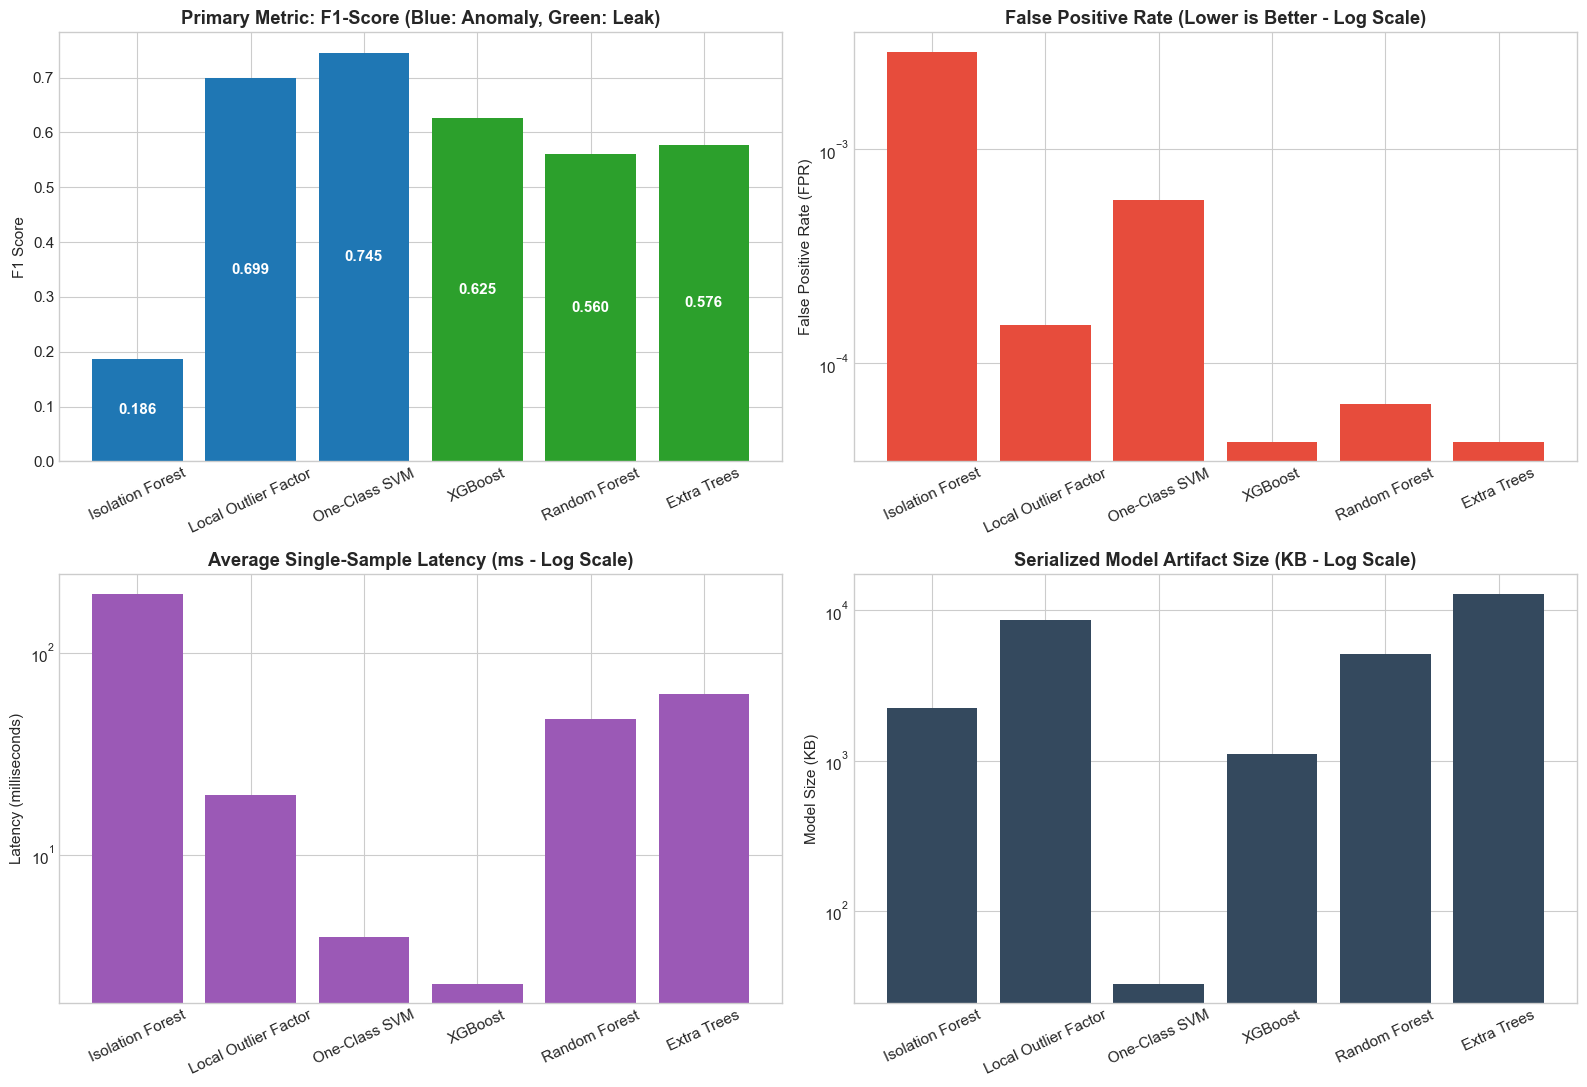

Chart saved to ../results\figures\06_final_model_comparison.png


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Primary Quality (F1 Score)
models_all = df_operational['Model']
f1s = df_operational['Primary F1']
colors = ['#1f77b4' if d == 'Abnormal Consumption' else '#2ca02c' for d in df_operational['Domain']]
axes[0, 0].bar(models_all, f1s, color=colors)
axes[0, 0].set_title("Primary Metric: F1-Score (Blue: Anomaly, Green: Leak)", fontweight='bold')
axes[0, 0].set_ylabel("F1 Score")
axes[0, 0].tick_params(axis='x', rotation=25)
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width()/2., p.get_height()/2),
                         ha='center', va='center', color='white', fontweight='bold')

# 2. False Positive Rate (Log scale)
fprs = df_operational['False Positive Rate'].clip(lower=1e-5)
axes[0, 1].bar(models_all, fprs, color='#e74c3c')
axes[0, 1].set_title("False Positive Rate (Lower is Better - Log Scale)", fontweight='bold')
axes[0, 1].set_ylabel("False Positive Rate (FPR)")
axes[0, 1].set_yscale('log')
axes[0, 1].tick_params(axis='x', rotation=25)

# 3. Inference Latency (Log scale)
lat = df_operational['Avg Latency (ms)']
axes[1, 0].bar(models_all, lat, color='#9b59b6')
axes[1, 0].set_title("Average Single-Sample Latency (ms - Log Scale)", fontweight='bold')
axes[1, 0].set_ylabel("Latency (milliseconds)")
axes[1, 0].set_yscale('log')
axes[1, 0].tick_params(axis='x', rotation=25)

# 4. Model Footprint (Size in KB)
sizes = df_operational['Model Size (KB)']
axes[1, 1].bar(models_all, sizes, color='#34495e')
axes[1, 1].set_title("Serialized Model Artifact Size (KB - Log Scale)", fontweight='bold')
axes[1, 1].set_ylabel("Model Size (KB)")
axes[1, 1].set_yscale('log')
axes[1, 1].tick_params(axis='x', rotation=25)

plt.tight_layout()
fig_path = os.path.join(base_res, 'figures', '06_final_model_comparison.png')
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Chart saved to {fig_path}")


## 6. Critical Limitations and Operational Deployment Notes
1. **Synthetic Data Realism:** While the synthetic simulation models physical hydraulics ($\Delta P = R \cdot Q^2$) and sensor failures, real-world SCADA environments feature complex pipe corrosion, temperature-dependent viscosity, and diurnal seasonal drift that require continuous retraining.
2. **Extreme Class Imbalance:** The positive event rates (0.32% anomaly, 0.27% leak) reflect actual distribution networks. In small test partitions, event-level counts (e.g. 2 test leak events) yield high row-level statistical confidence but event-level sample sizes are limited.
3. **Class 0 Semantic Boundaries:** In the leak classification dataset, non-leak anomalies (`night_use` and `unexpected_spike`) are absorbed into Class 0 (Non-Actionable Baseline). In future iterations, a 5-class architecture distinguishing non-actionable usage from pristine baselines could further streamline facility management.
